In [1]:
# Install catalax
# !pip install catalax

In [2]:
import warnings

import numpyro.distributions as dist

import catalax as ctx
import catalax.mcmc as cmc

warnings.filterwarnings("ignore")

# Hamiltonian Monte Carlo (HMC) Parameter Estimation

This notebook demonstrates how to use Catalax for Bayesian parameter estimation using Hamiltonian Monte Carlo (HMC) sampling. We'll work with a simple Michaelis-Menten enzyme kinetics model and estimate the parameters `v_max` and `K_m` from noisy experimental data.

## Overview
1. Define a simple enzyme kinetics model with Michaelis-Menten kinetics
2. Load the data and add 5 % proportional noise
3. Set up Bayesian priors for the parameters
4. Describe the observation noise and perform HMC sampling
5. Analyze and visualize the results, including the inferred noise level


In [3]:
# Initialize the model
model = ctx.Model(name="Simple menten model")

# Add species
model.add_state("s1")

# Add ODEs
model.add_ode("s1", "- (v_max * s1) / ( K_m + s1)")

# Prepare the model for bayes and define priors
model.parameters["v_max"].value = 7.0
model.parameters["K_m"].value = 100.0

# Save the model
model.save("./models/", "menten_model")

model

,name,symbol,type
0,s1,s1,None


,name,symbol,value,constant,initial_value,equation,lower_bound,upper_bound,hdi
0,K_m,K_m,100.0,False,None,None,None,None,None
1,v_max,v_max,7.0,False,None,None,None,None,None


""


""


""



Model(
    name='Simple menten model',
    odes=DottedDict({'s1': ODE(equation=-s1*v_max/(K_m + s1), parameters=DottedDict({'K_m': Parameter(name='K_m', symbol=K_m, value=100.0, constant=False, identifiability=None, initial_value=None, equation=None, lower_bound=None, upper_bound=None, hdi=None, prior=None), 'v_max': Parameter(name='v_max', symbol=v_max, value=7.0, constant=False, identifiability=None, initial_value=None, equation=None, lower_bound=None, upper_bound=None, hdi=None, prior=None)}), state=State(name='s1', symbol=s1, type=None), observable=True)}),
    states=,
    parameters=,
    reactions=,
    constants=,
    assignments=
)

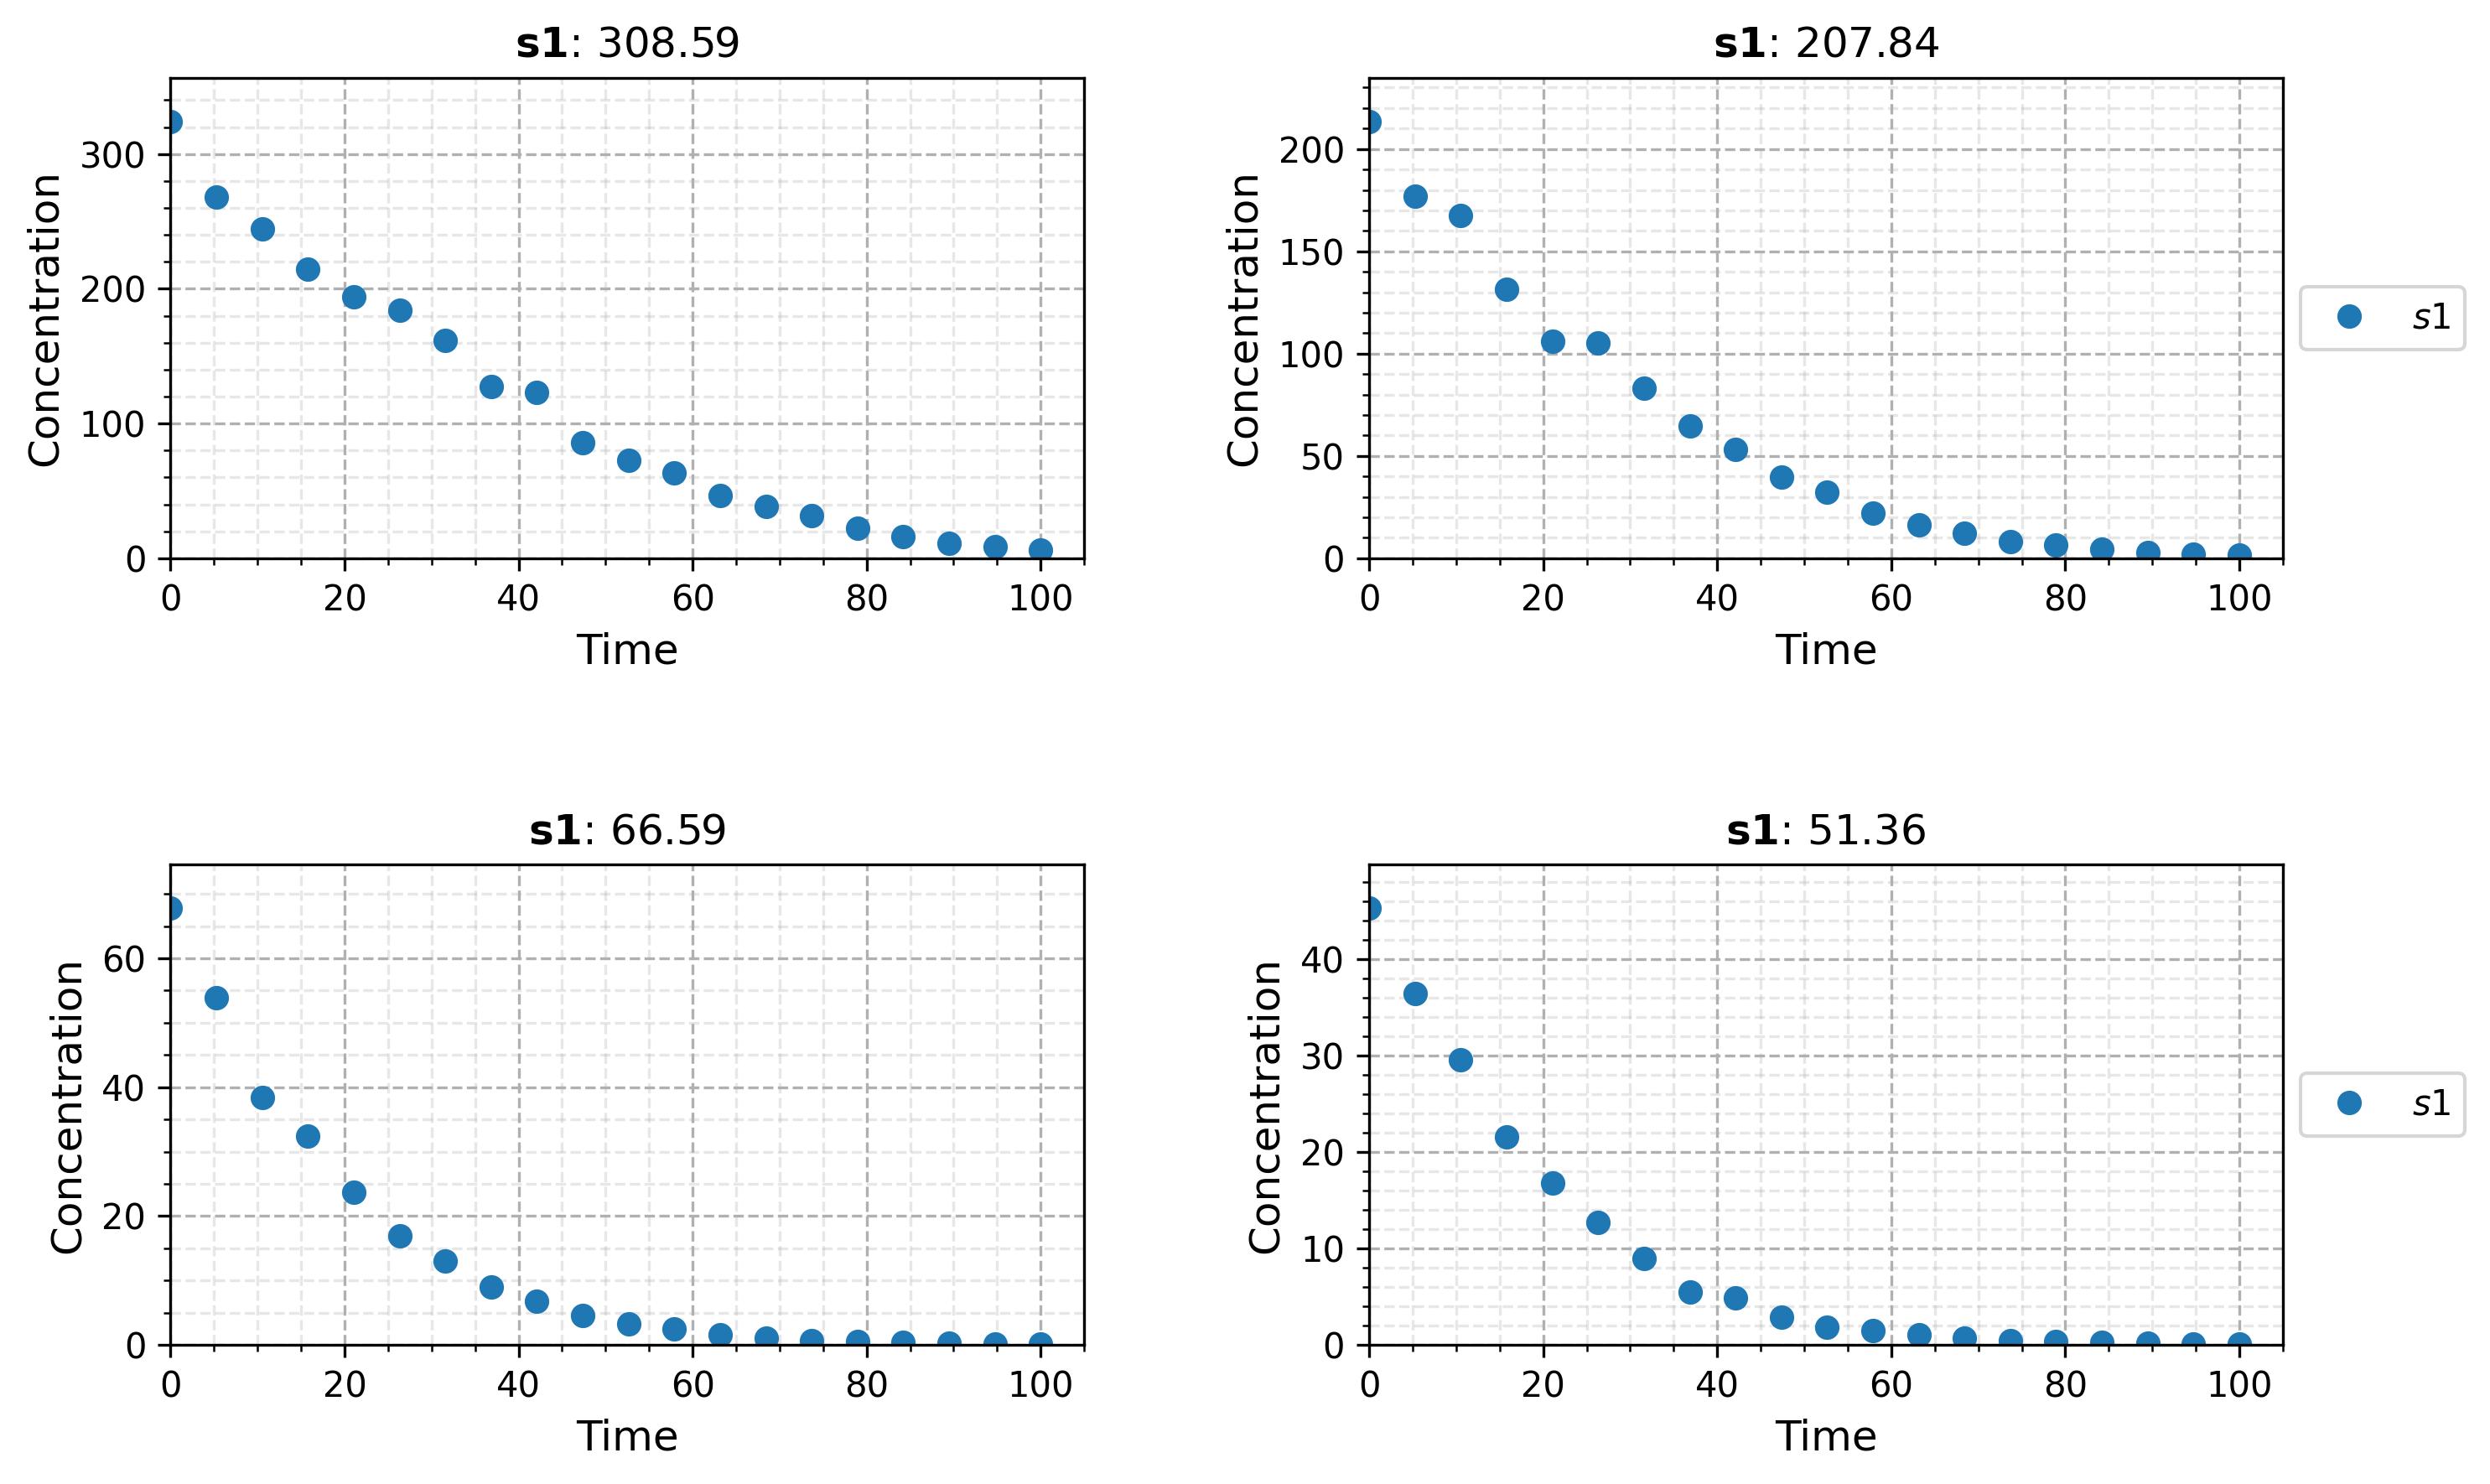

In [4]:
# Load the datasets
dataset = ctx.Dataset.from_croissant("datasets/croissant_dataset.zip")

# Add proportional noise to make the data more realistic: y * (1 + N(0, 0.05)),
# i.e. a relative standard deviation (cv) of 5 %
dataset = dataset.augment(
    n_augmentations=1,
    seed=0,
    sigma=5e-2,
    append=False,
    multiplicative=True,
)

dataset.plot(
    measurement_ids=[m.id for m in dataset.measurements[:4]],
    show=True,
)

In [5]:
# Define Priors
model.parameters["v_max"].prior = cmc.priors.Uniform(low=1e-6, high=200.0)
model.parameters["K_m"].prior = cmc.priors.Uniform(low=1e-6, high=1e3)

# Save the model and its priors
model.save("./models/", "menten_model_w_priors")

## Observation noise

The noise model says how large the measurement error is at each point: `Proportional(cv, floor)` has the standard deviation $\sqrt{\text{floor}^2 + (\text{cv} \cdot \hat y)^2}$, the usual model for assays whose error grows with the measured amount. Each field is either a fixed number or a prior; priors are sampled together with the kinetic parameters.

Here the noise is purely proportional, so `cv` gets a wide prior (median 10 %, roughly 1.4–70 % at two standard deviations) and `floor` is fixed at a small value, which only keeps the standard deviation positive where the prediction approaches zero. With `likelihood=dist.Normal` the noise model's standard deviation is the standard deviation of the likelihood.


In [6]:
noise = ctx.noise.Proportional(
    cv=cmc.priors.LogNormal(mu=0.1, sigma=1.0),  # sampled
    floor=0.01,                                  # fixed
)

# Perform MCMC simulation
hmc = cmc.HMC(
    num_warmup=1000,
    num_samples=1000,
    likelihood=dist.Normal,
    dt0=0.1,
    max_steps=64**4,
    verbose=1,
)

results = hmc.run(model=model, dataset=dataset, noise=noise)

# Apply the median posterior to the model
fitted_model = results.get_fitted_model()

# Print the summary
results.summary()


🚀 Running MCMC



  0%|          | 0/2000 [00:00<?, ?it/s]

  0%|          | 0/2000 [00:00<?, ?it/s]

  0%|          | 0/2000 [00:00<?, ?it/s]

  0%|          | 0/2000 [00:00<?, ?it/s]

,mean,sd,hdi95_lb,hdi95_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
K_m,100.056,0.187,100,100,1599,1826,1.01,0.0047,0.0033
cv,0.04875,0.0007,0.047,0.05,1132,1282,1.00,2.1e-05,1.4e-05
v_max,7.0057,0.0096,7,7,1604,1800,1.00,0.00024,0.00017


The posterior of `cv` should sit close to the 5 % used to generate the noise: the data determine the noise level along with the kinetic parameters.


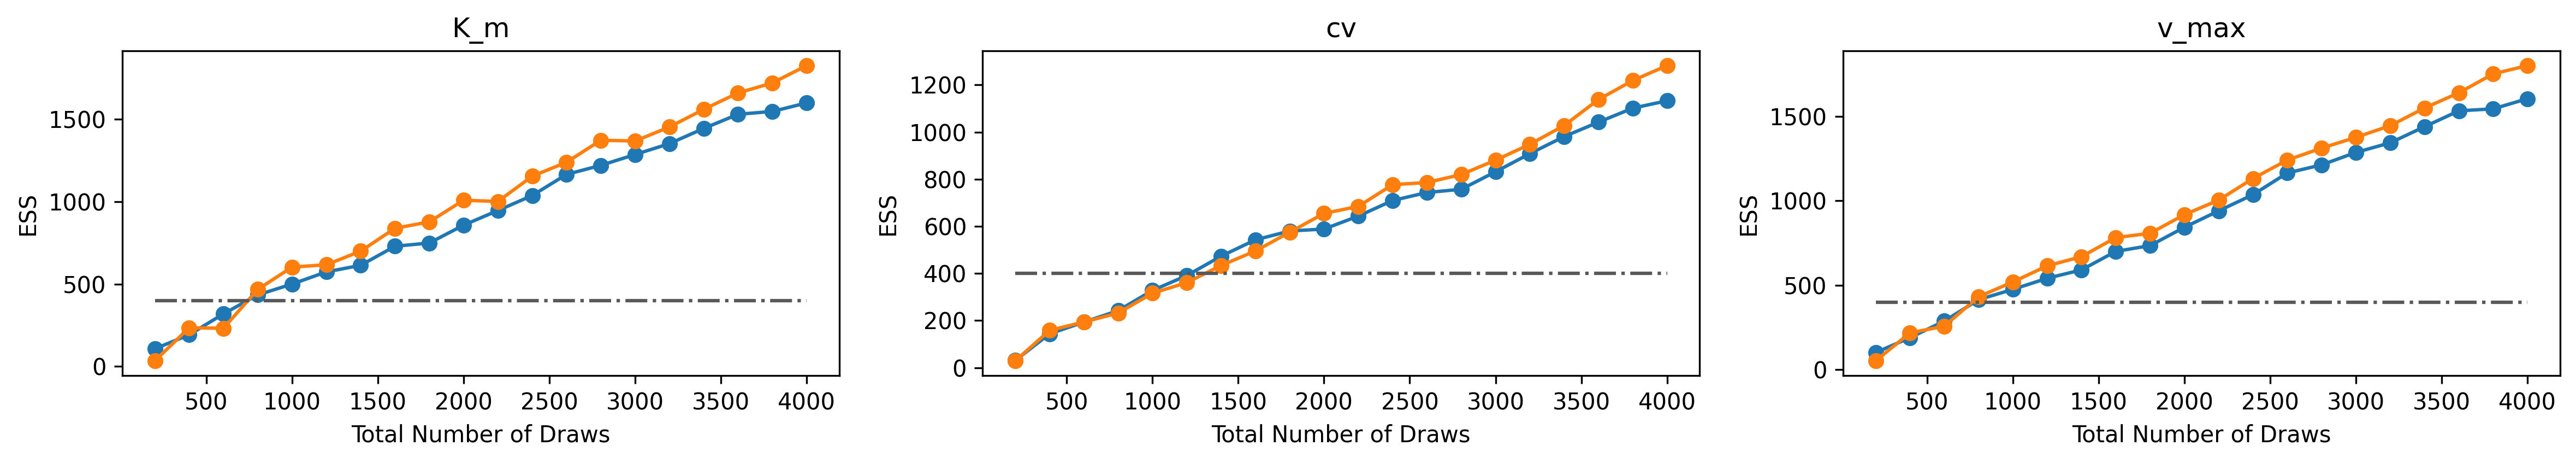

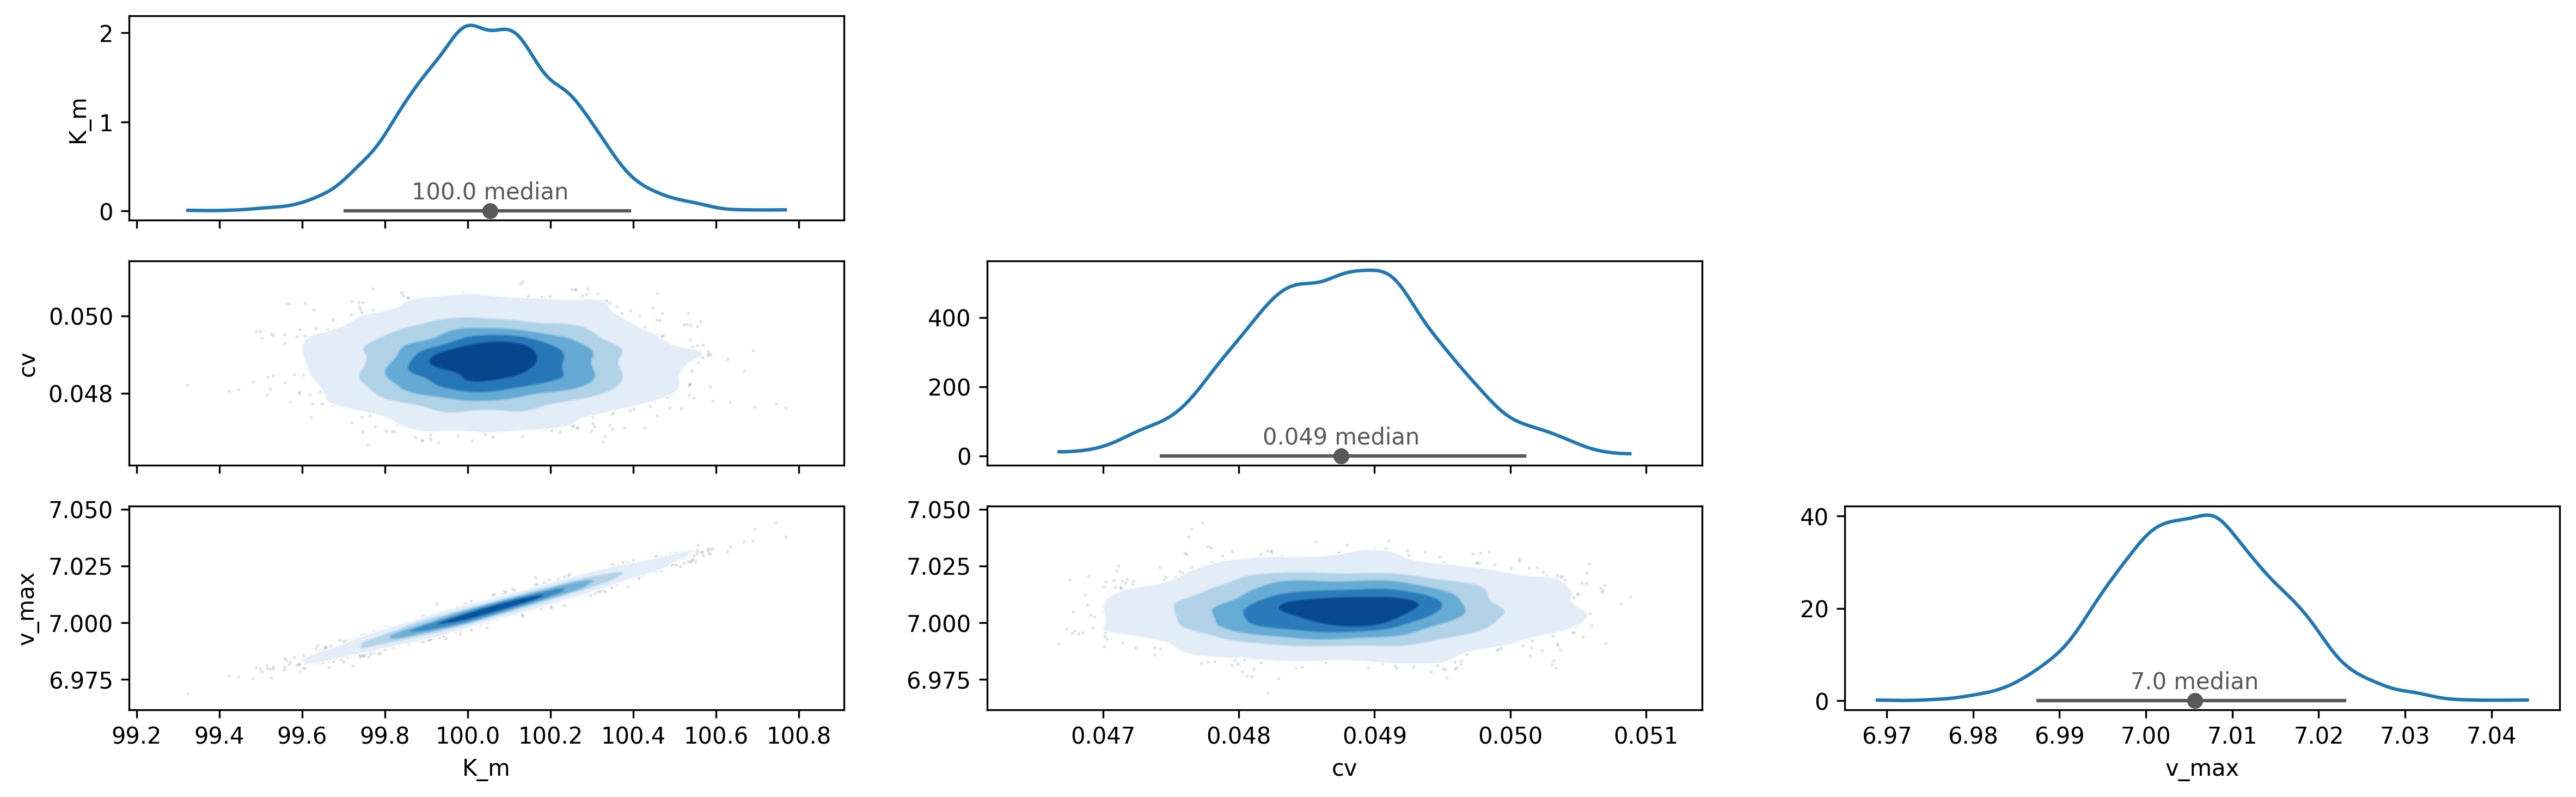

In [7]:
# Plot the trace
results.plot_ess(show=True)

# Plot the corner
results.plot_corner(show=True)

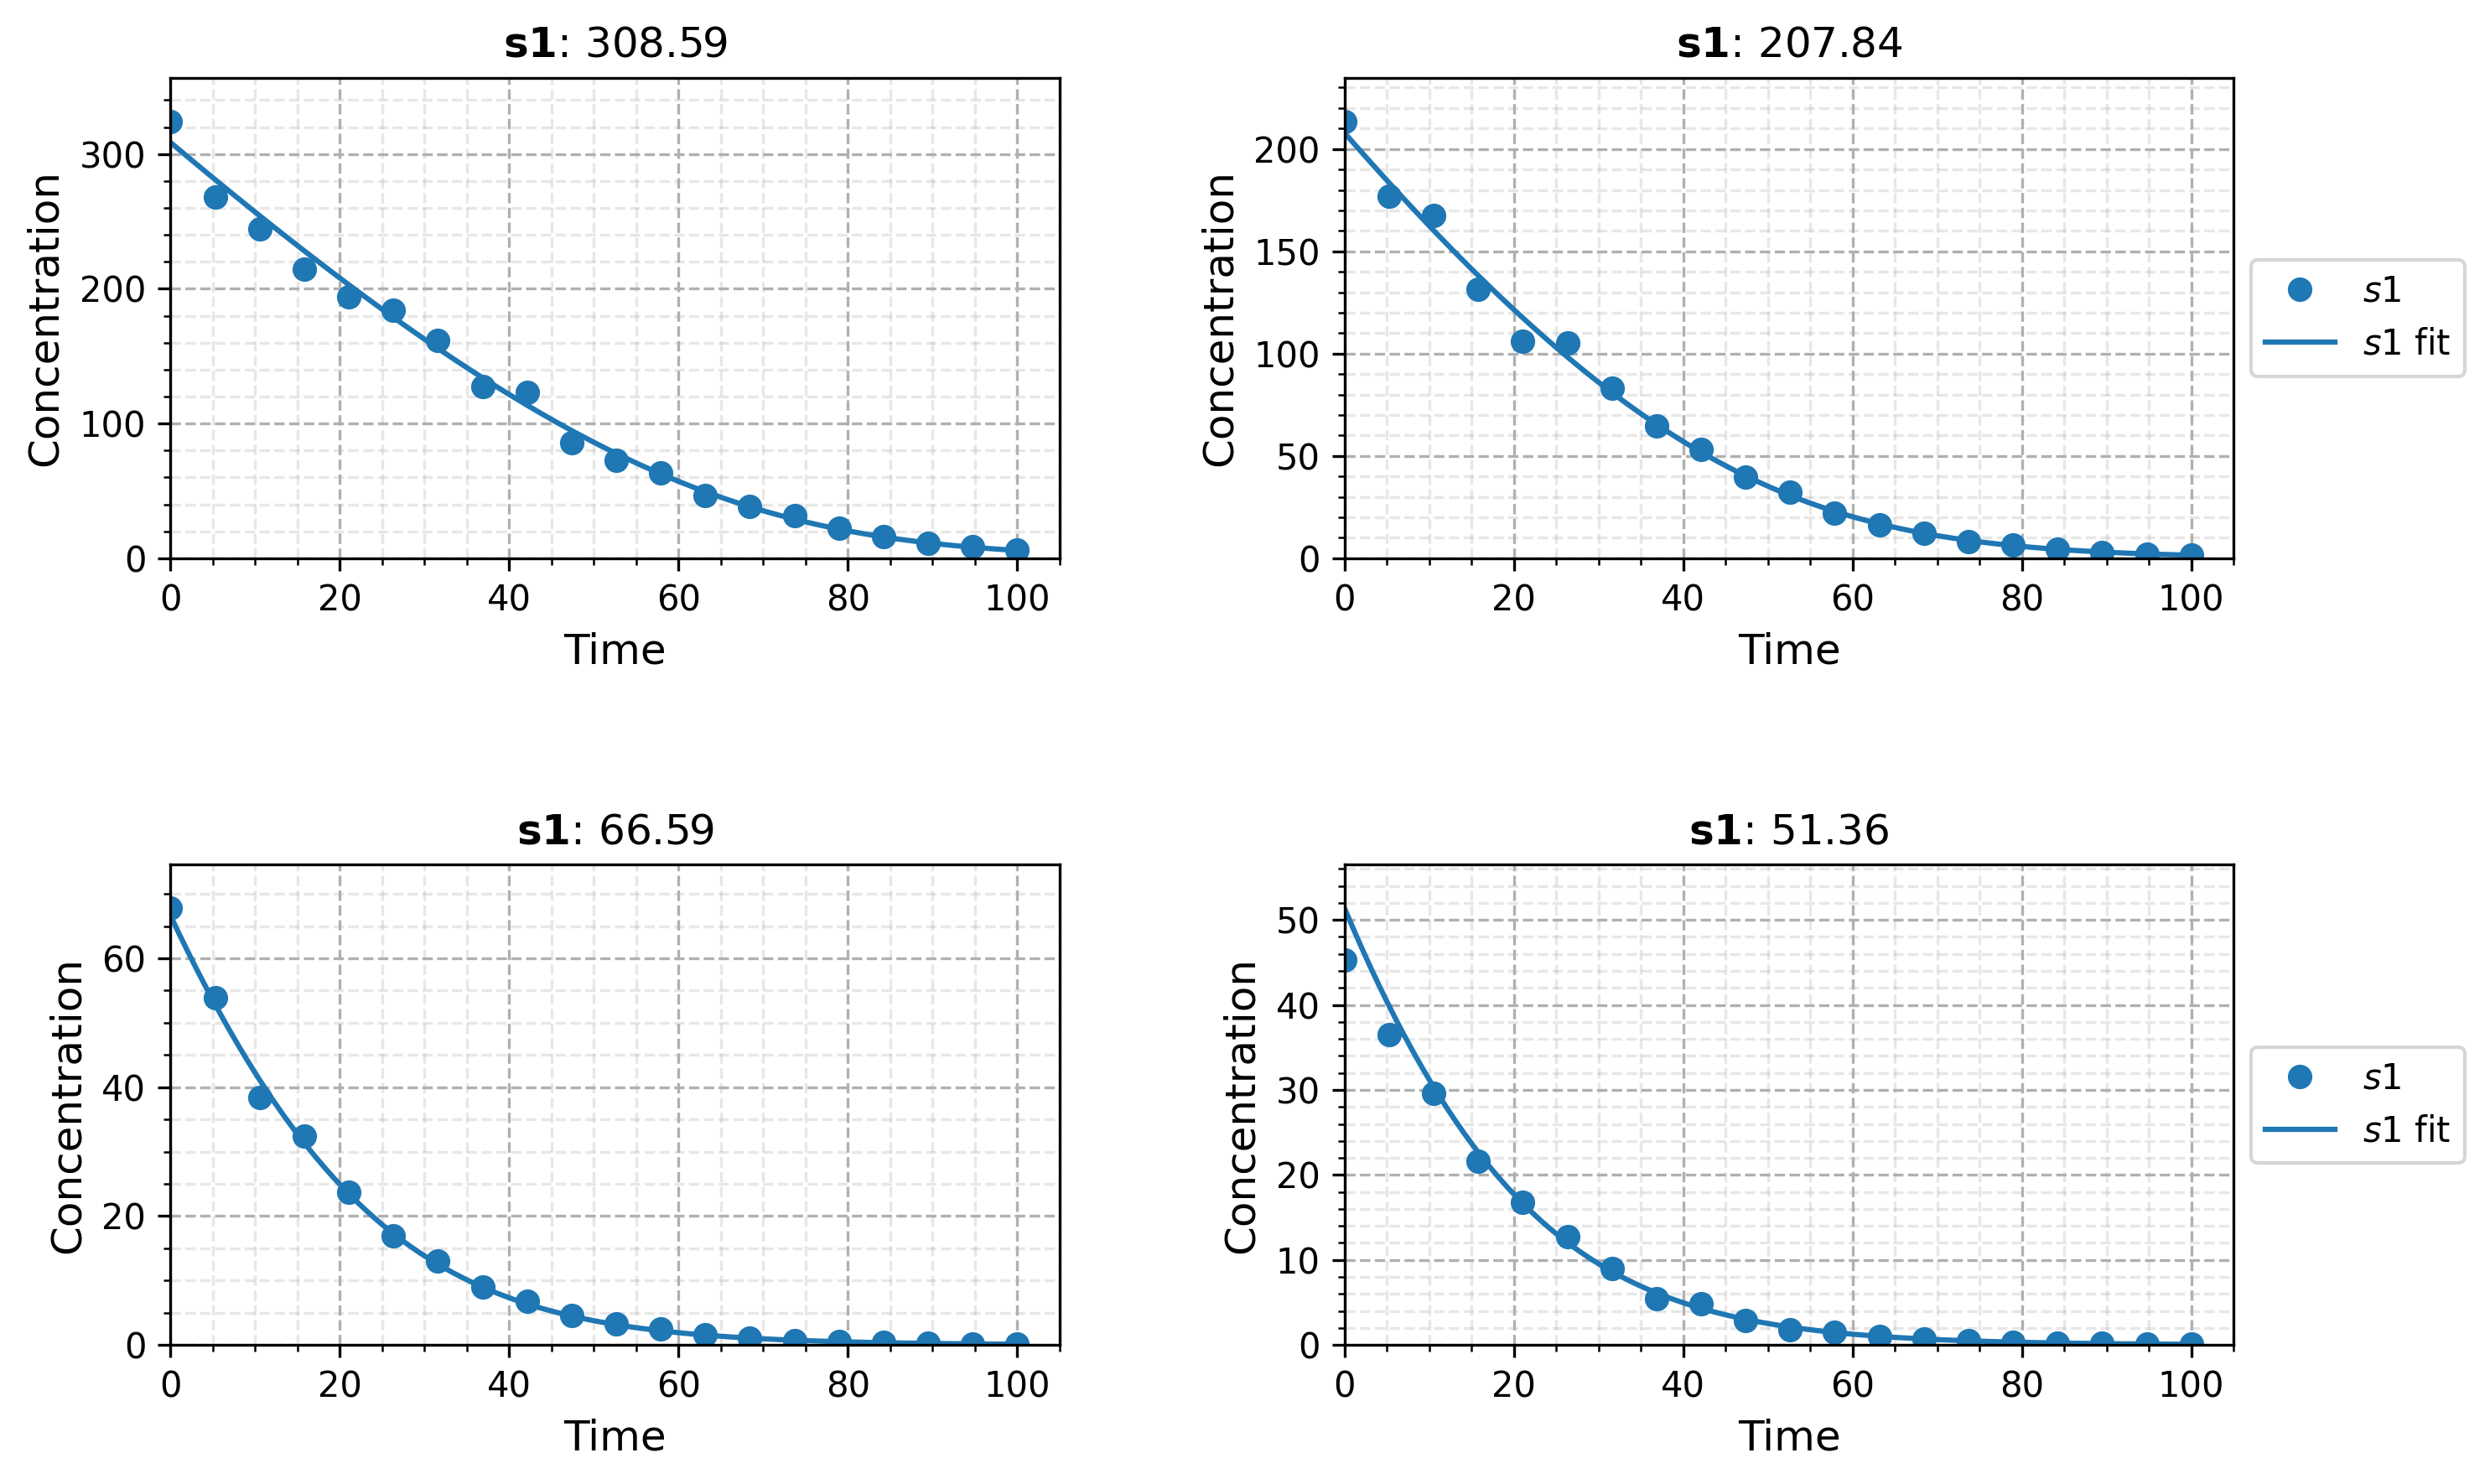

In [8]:
dataset.plot(
    predictor=fitted_model,
    measurement_ids=[m.id for m in dataset.measurements[:4]],
    show=True,
)